<a href="https://colab.research.google.com/github/sabarisrinath-boop/Bengaluru-House-Price-Prediction/blob/main/python_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import warnings
warnings.filterwarnings("ignore")



df=pd.read_csv("/content/Bengaluru_House_Data (1).csv")

In [ ]:
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.00


In [ ]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
df.tail()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [ ]:
df.shape

(13320, 9)

In [ ]:
df.dtypes

,0
area_type,object
availability,object
location,object
size,object
society,object
total_sqft,object
bath,float64
balcony,float64
price,float64


In [ ]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [ ]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [ ]:
df.isna().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


In [ ]:
df.availability.value_counts()

,count
availability,
Ready To Move,10581
18-Dec,307
18-May,295
18-Apr,271
18-Aug,200
...,...
16-Oct,1
17-Jan,1
16-Nov,1


In [ ]:
df.total_sqft.value_counts()

,count
total_sqft,
1200,843
1100,221
1500,205
2400,196
600,180
...,...
2920,1
5665.84,1
1369,1


In [ ]:
df['size'].value_counts()

,count
size,
2 BHK,5199
3 BHK,4310
4 Bedroom,826
4 BHK,591
3 Bedroom,547
1 BHK,538
2 Bedroom,329
5 Bedroom,297
6 Bedroom,191


In [ ]:
print("Mean Price:", df['price'].mean())

print("Median Price:", df['price'].median())

print("Mode Price:", df['price'].mode()[0])

Mean Price: 112.5656265015015
Median Price: 72.0
Mode Price: 75.0


In [ ]:
print("Standard Deviation:",
      df['price'].std())

print("Variance:",
      df['price'].var())

Standard Deviation: 148.9716737696744
Variance: 22192.559585738298


In [ ]:
area_analysis = df.groupby('area_type')['price'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

print(area_analysis)

                            mean  median    min     max  count
area_type                                                     
Built-up  Area        104.285498    70.0   9.00  2050.0   2418
Carpet  Area           89.502356    70.0  13.00   500.0     87
Plot  Area            208.495486   140.0   8.44  3600.0   2025
Super built-up  Area   92.971757    65.0   8.00  2912.0   8790


In [ ]:
total_houses = len(df)

low_price = (df['price'] < 50).sum()
medium_price = (
    (df['price'] >= 50) &
    (df['price'] < 100)
).sum()
high_price = (df['price'] >= 100).sum()

print("Probability of low-price houses:",
      round(low_price / total_houses, 3))

print("Probability of medium-price houses:",
      round(medium_price / total_houses, 3))

Probability of low-price houses: 0.246
Probability of medium-price houses: 0.433


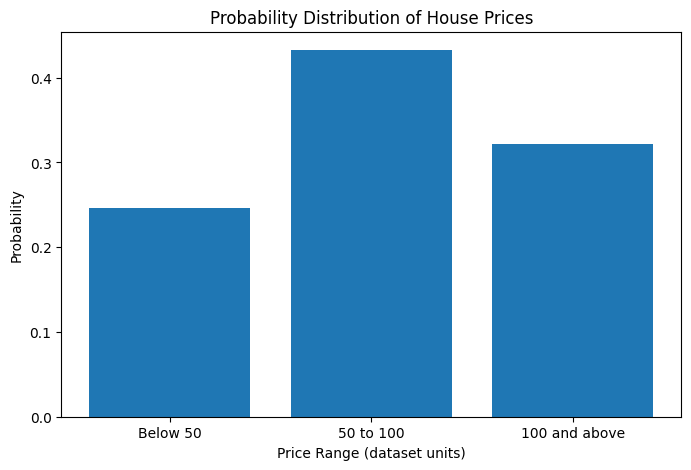

In [ ]:
categories = ['Below 50', '50 to 100', '100 and above']

probabilities = [
    low_price / total_houses,
    medium_price / total_houses,
    high_price / total_houses
]

plt.figure(figsize=(8, 5))

plt.bar(categories, probabilities)

plt.title("Probability Distribution of House Prices")
plt.xlabel("Price Range (dataset units)")
plt.ylabel("Probability")

plt.show()

In [ ]:
location_probability = (
    df['location'].value_counts(normalize=True) * 100
)

print(location_probability.head(10))

location
Whitefield               4.054358
Sarjapur  Road           2.995720
Electronic City          2.267437
Kanakpura Road           2.049703
Thanisandra              1.756889
Yelahanka                1.599219
Uttarahalli              1.396501
Hebbal                   1.328929
Marathahalli             1.313912
Raja Rajeshwari Nagar    1.283880
Name: proportion, dtype: float64


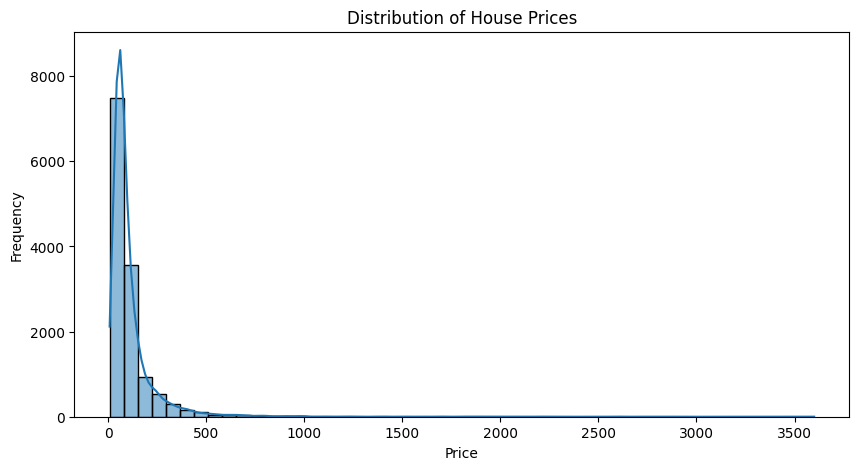

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

location
Cubbon Road          1900.0
Yemlur               1675.0
Ashok Nagar          1486.0
Church Street        1068.0
D Souza Layout       1015.0
Sindhi Colony         988.0
Srinivas Colony       922.0
Binnamangala          900.0
Cunningham Road       800.0
Hunasamaranahalli     787.5
Name: price, dtype: float64


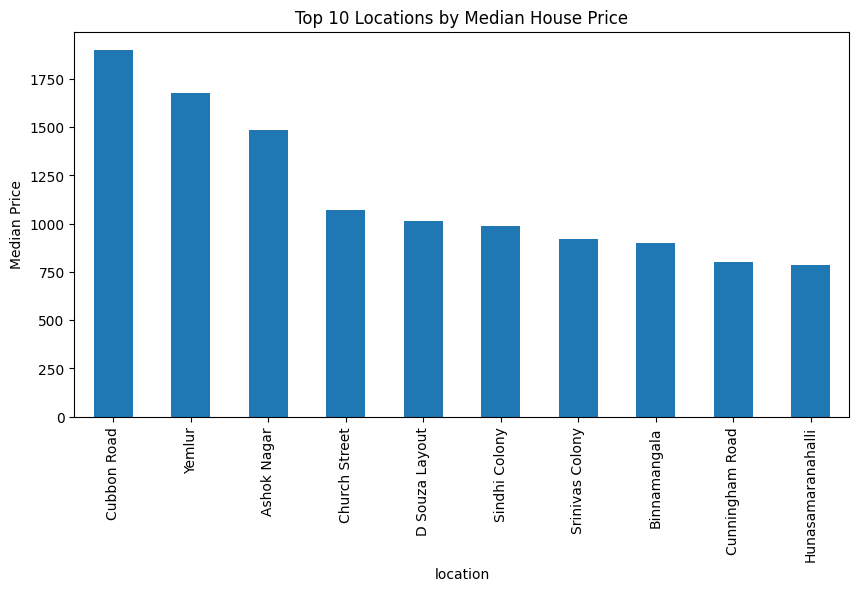

In [ ]:
location_price = df.groupby('location')['price'].median()

top_locations = location_price.sort_values(
    ascending=False
).head(10)

print(top_locations)

top_locations.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Top 10 Locations by Median House Price")
plt.ylabel("Median Price")


plt.show()

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['price'] < lower) |
    (df['price'] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 1276


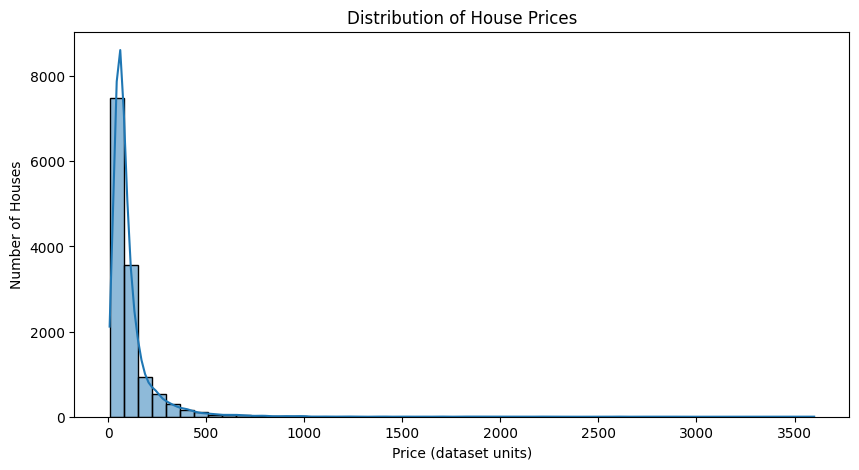

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price (dataset units)")
plt.ylabel("Number of Houses")

plt.show()

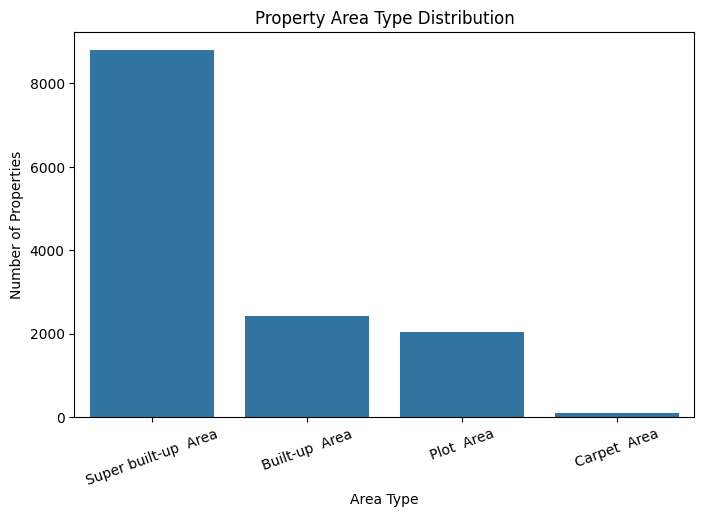

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='area_type',
    order=df['area_type'].value_counts().index
)

plt.title("Property Area Type Distribution")
plt.xlabel("Area Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=20)

plt.show()

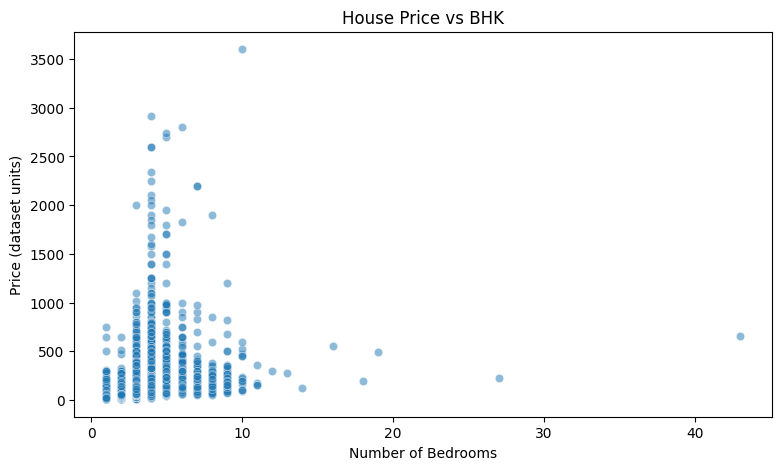

In [ ]:
df['bhk'] = pd.to_numeric(
    df['size'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='bhk',
    y='price',
    alpha=0.5
)

plt.title("House Price vs BHK")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (dataset units)")

plt.show()

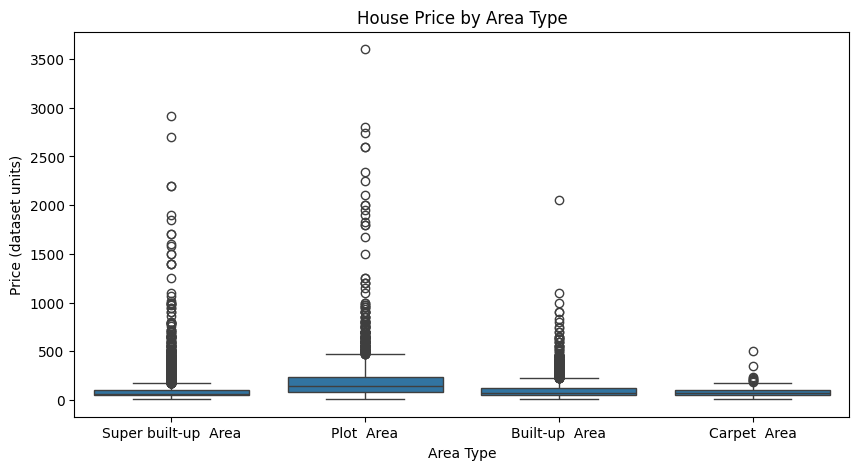

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='area_type',
    y='price'
)

plt.title("House Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Price (dataset units)")


plt.show()

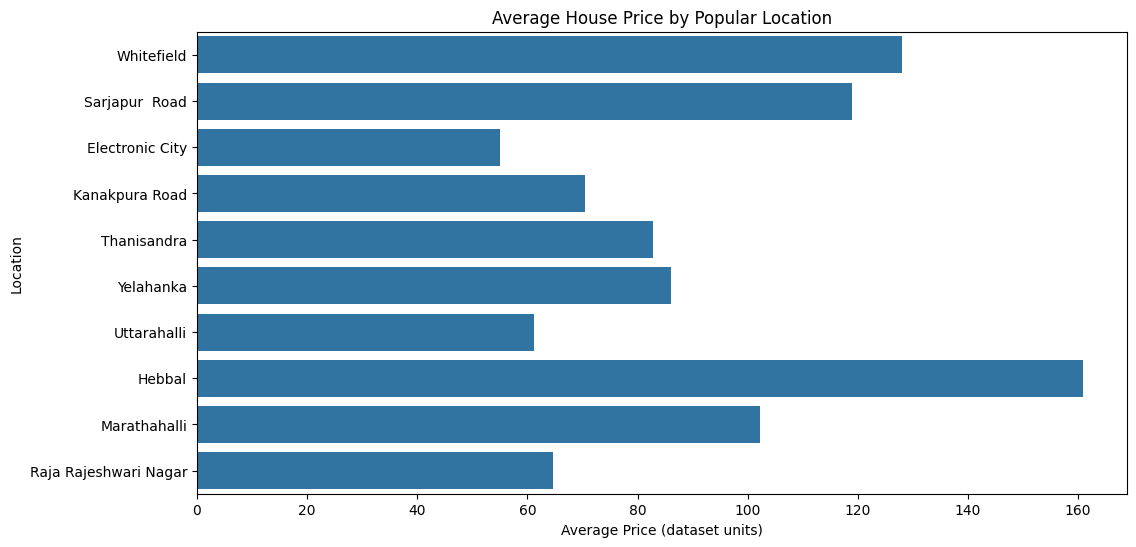

In [ ]:
location_data = (
    df.groupby('location')['price']
    .agg(['mean', 'count'])
    .reset_index()
)

location_data = location_data[
    location_data['count'] >= 30
]

top_locations = location_data.nlargest(
    10, 'count'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_locations,
    x='mean',
     y='location'
)

plt.title("Average House Price by Popular Location")
plt.xlabel("Average Price (dataset units)")
plt.ylabel("Location")

plt.show()

<Axes: >

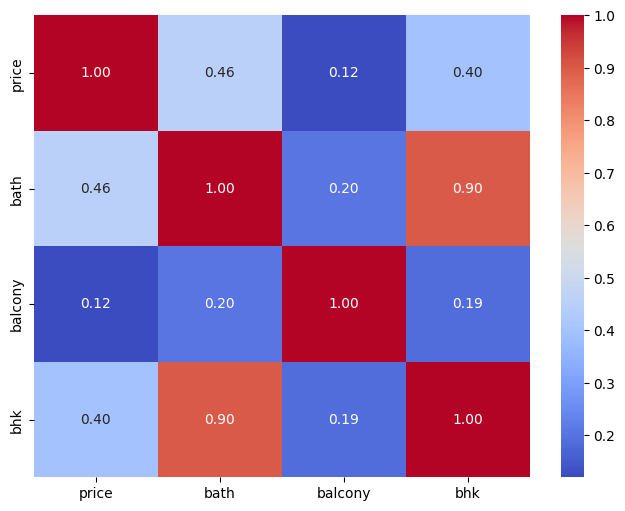

In [ ]:

numeric_df = df[
    ['price', 'bath', 'balcony']
].copy()

numeric_df['bhk'] = df['size'].astype(str).str.extract(
    r'(\d+)'
)

numeric_df['bhk'] = pd.to_numeric(
    numeric_df['bhk'],
    errors='coerce'
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)